# Categorical Label Encoding

**Student ID:** IT25103567  
**Assigned Preprocessing Technique:** Categorical Label Encoding

## 1. Introduction and Objective

Categorical label encoding is a preprocessing technique used to convert
categorical class names into numerical labels that can be processed by
machine-learning algorithms.

In this project, the dataset contains 20 disease classes. Each disease
class is assigned a unique numerical label from 0 to 19.

The same label mapping is maintained for both training and validation
datasets to ensure consistency throughout the machine-learning pipeline.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
##Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
##Define Project Path
import os

project_path = "/content/drive/MyDrive/member 3/Crop Disease AI project"

print("Project path:", project_path)
print("Project exists:", os.path.exists(project_path))

Project path: /content/drive/MyDrive/member 3/Crop Disease AI project
Project exists: True


In [4]:
##Define Dataset Path
member3_path = os.path.join(
    project_path,
    "Member_03_IT25103371"
)

print("Member 3 path:", member3_path)
print("Member 3 exists:", os.path.exists(member3_path))

Member 3 path: /content/drive/MyDrive/member 3/Crop Disease AI project/Member_03_IT25103371
Member 3 exists: False


In [5]:
##Access Member 3 outputs
member3_output_path = os.path.join(
    member3_path,
    "Outputs"
)

print("Member 3 Outputs path:")
print(member3_output_path)

print("\nOutputs exists:", os.path.exists(member3_output_path))

Member 3 Outputs path:
/content/drive/MyDrive/member 3/Crop Disease AI project/Member_03_IT25103371/Outputs

Outputs exists: False


In [6]:
## Access Augmented Dataset

augmented_path = "/content/drive/MyDrive/member 3/targeted_augmented_images"

print("Augmented dataset path:")
print(augmented_path)

print("\nAugmented dataset exists:", os.path.exists(augmented_path))

Augmented dataset path:
/content/drive/MyDrive/member 3/targeted_augmented_images

Augmented dataset exists: True


In [7]:
## Inspect Member 3 Augmented Classes

augmented_classes = sorted([
    folder
    for folder in os.listdir(augmented_path)
    if os.path.isdir(os.path.join(augmented_path, folder))
])

print("Number of augmented classes:", len(augmented_classes))

print("\nAugmented classes:")
for i, class_name in enumerate(augmented_classes, start=1):
    print(i, "->", class_name)

Number of augmented classes: 12

Augmented classes:
1 -> Healthy Wheat
2 -> Healthy cotton
3 -> Mosaic sugarcane
4 -> Wheat Stem fly
5 -> Wheat black rust
6 -> Wheat powdery mildew
7 -> Wilt
8 -> bacterial_blight in Cotton
9 -> cotton mealy bug
10 -> maize fall armyworm
11 -> maize stem borer
12 -> red cotton bug


In [8]:
## Load Final Training Class Distribution

distribution_file = "/content/drive/MyDrive/member 3/final_training_class_distribution.csv"

final_distribution = pd.read_csv(distribution_file)

print("Final training class distribution:")
display(final_distribution)

Final training class distribution:


,Class,Original_Count,Augmented_Count,Final_Count
0,Brownspot,1640,0,1640
1,Becterial Blight in Rice,1584,0,1584
2,Rice Blast,1440,0,1440
3,Tungro,1308,0,1308
4,Healthy Maize,1162,0,1162
5,RedRot sugarcane,592,0,592
6,Gray_Leaf_Spot,574,0,574
7,Sugarcane Healthy,522,0,522
8,bacterial_blight in Cotton,489,11,500
9,Mosaic sugarcane,462,38,500


In [9]:
##Identify the 20 Disease Classes
class_names = sorted(
    final_distribution["Class"].astype(str).tolist()
)

print("Number of classes:", len(class_names))

print("\n20 Disease Classes:")
for i, class_name in enumerate(class_names):
    print(i, "->", class_name)

Number of classes: 20

20 Disease Classes:
0 -> Becterial Blight in Rice
1 -> Brownspot
2 -> Gray_Leaf_Spot
3 -> Healthy Maize
4 -> Healthy Wheat
5 -> Healthy cotton
6 -> Mosaic sugarcane
7 -> RedRot sugarcane
8 -> Rice Blast
9 -> Sugarcane Healthy
10 -> Tungro
11 -> Wheat Stem fly
12 -> Wheat black rust
13 -> Wheat powdery mildew
14 -> Wilt
15 -> bacterial_blight in Cotton
16 -> cotton mealy bug
17 -> maize fall armyworm
18 -> maize stem borer
19 -> red cotton bug


In [10]:
##Create Label Encoder
label_encoder = LabelEncoder()

label_encoder.fit(class_names)

print("Label Encoder created successfully!")
print("Number of classes:", len(label_encoder.classes_))

Label Encoder created successfully!
Number of classes: 20


In [11]:
##Generate Label Mapping
label_mapping = pd.DataFrame({
    "Class Name": label_encoder.classes_,
    "Encoded Label": label_encoder.transform(
        label_encoder.classes_
    )
})

display(label_mapping)

,Class Name,Encoded Label
0,Becterial Blight in Rice,0
1,Brownspot,1
2,Gray_Leaf_Spot,2
3,Healthy Maize,3
4,Healthy Wheat,4
5,Healthy cotton,5
6,Mosaic sugarcane,6
7,RedRot sugarcane,7
8,Rice Blast,8
9,Sugarcane Healthy,9


In [12]:
##Verify Label Encoding
print("Minimum encoded label:",
      label_mapping["Encoded Label"].min())

print("Maximum encoded label:",
      label_mapping["Encoded Label"].max())

print("Number of unique labels:",
      label_mapping["Encoded Label"].nunique())

print("Number of classes:",
      len(label_mapping))

Minimum encoded label: 0
Maximum encoded label: 19
Number of unique labels: 20
Number of classes: 20


In [13]:
##Encode Member 3 Augmented Labels
augmented_label_data = []

for class_name in augmented_classes:

    numerical_label = label_encoder.transform(
        [class_name]
    )[0]

    class_path = os.path.join(
        augmented_path,
        class_name
    )

    for file_name in os.listdir(class_path):

        file_path = os.path.join(
            class_path,
            file_name
        )

        if os.path.isfile(file_path):

            augmented_label_data.append({
                "File Path": file_path,
                "Original Class": class_name,
                "Encoded Label": numerical_label
            })

augmented_labels_df = pd.DataFrame(
    augmented_label_data
)

print("Number of augmented samples:",
      len(augmented_labels_df))

display(augmented_labels_df.head())

Number of augmented samples: 3160


,File Path,Original Class,Encoded Label
0,/content/drive/MyDrive/member 3/targeted_augme...,Healthy Wheat,4
1,/content/drive/MyDrive/member 3/targeted_augme...,Healthy Wheat,4
2,/content/drive/MyDrive/member 3/targeted_augme...,Healthy Wheat,4
3,/content/drive/MyDrive/member 3/targeted_augme...,Healthy Wheat,4
4,/content/drive/MyDrive/member 3/targeted_augme...,Healthy Wheat,4


In [14]:
##Verify Augmented Encoded Labels
print("Unique encoded labels in augmented data:")

print(
    sorted(
        augmented_labels_df["Encoded Label"].unique()
    )
)

print(
    "\nNumber of encoded classes:",
    augmented_labels_df["Encoded Label"].nunique()
)

Unique encoded labels in augmented data:
[np.int64(4), np.int64(5), np.int64(6), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19)]

Number of encoded classes: 12


## EDA Interpretation

### 1. Original Class Distribution – Bar Chart

The bar chart shows the sample distribution across the 20 original disease classes with original lables. It shows that the number of samples varies between classes.

### 2. Encoded Label Distribution – Bar Chart

The bar chart shows the same 20 classes using encoded labels from 0 to 19. The sample counts remain unchanged, confirming that label encoding changes only the class representation.

### 3. Augmented vs Non-Augmented Samples – Stacked Bar Chart

The stacked bar chart shows the non-augmented and augmented samples for each encoded label. It demonstrates that the encoded labels are consistently used for both types of samples.

### 4. Augmented Class Proportion – Pie Chart

The pie chart shows the proportion of samples among the 12 augmented classes using their encoded labels. It shows the relative contribution of each augmented class.

### Overall Finding

The EDA confirms that the 20 categorical disease classes are consistently represented by numerical labels from 0 to 19. The encoding changes the representation of the classes without changing their sample counts.

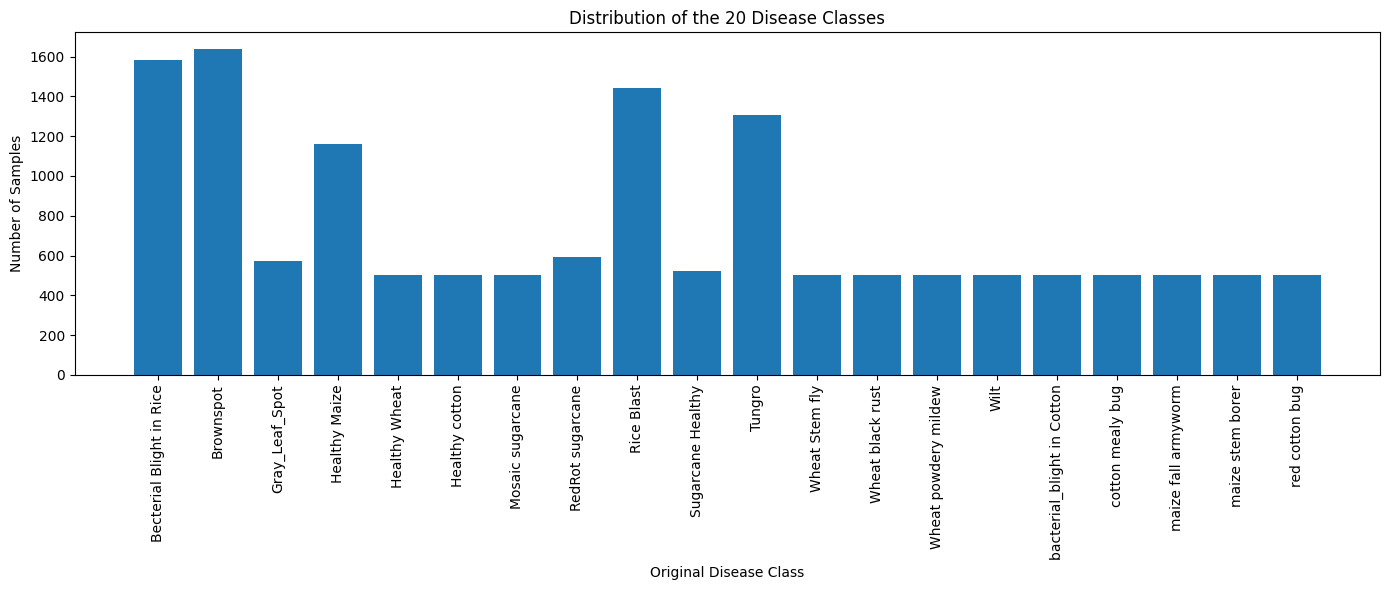

In [15]:
## EDA 1: Original Class Distribution

# Arrange the classes in the same order used by LabelEncoder
eda1_distribution = final_distribution.copy()

eda1_distribution["Encoded Label"] = (
    eda1_distribution["Class"].map(
        dict(zip(
            label_encoder.classes_,
            label_encoder.transform(label_encoder.classes_)
        ))
    )
)

# Sort according to encoded labels 0–19
eda1_distribution = eda1_distribution.sort_values("Encoded Label")

# Plot
plt.figure(figsize=(14, 6))

plt.bar(
    eda1_distribution["Class"],
    eda1_distribution["Final_Count"]
)

plt.xlabel("Original Disease Class")
plt.ylabel("Number of Samples")
plt.title("Distribution of the 20 Disease Classes")

plt.xticks(rotation=90)

plt.tight_layout()

plt.savefig(
    "EDA_1_Original_Class_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

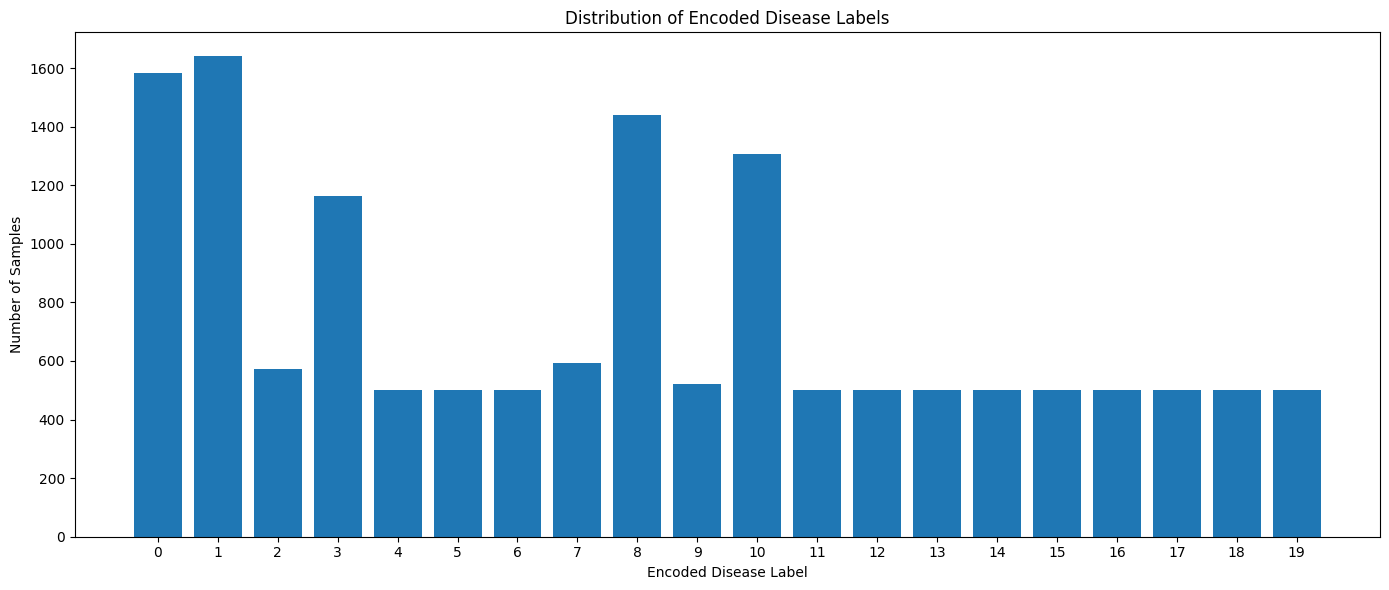

In [16]:
## EDA 2: Encoded Label Distribution

# Map each disease class to its encoded label
encoded_distribution = final_distribution.copy()

encoded_distribution["Encoded Label"] = (
    encoded_distribution["Class"].map(
        dict(zip(
            label_encoder.classes_,
            label_encoder.transform(label_encoder.classes_)
        ))
    )
)

# Sort according to encoded labels 0–19
encoded_distribution = encoded_distribution.sort_values("Encoded Label")

plt.figure(figsize=(14, 6))

plt.bar(
    encoded_distribution["Encoded Label"],
    encoded_distribution["Final_Count"]
)

plt.xlabel("Encoded Disease Label")
plt.ylabel("Number of Samples")
plt.title("Distribution of Encoded Disease Labels")

plt.xticks(range(20))

plt.tight_layout()

plt.savefig(
    "EDA_2_Encoded_Label_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

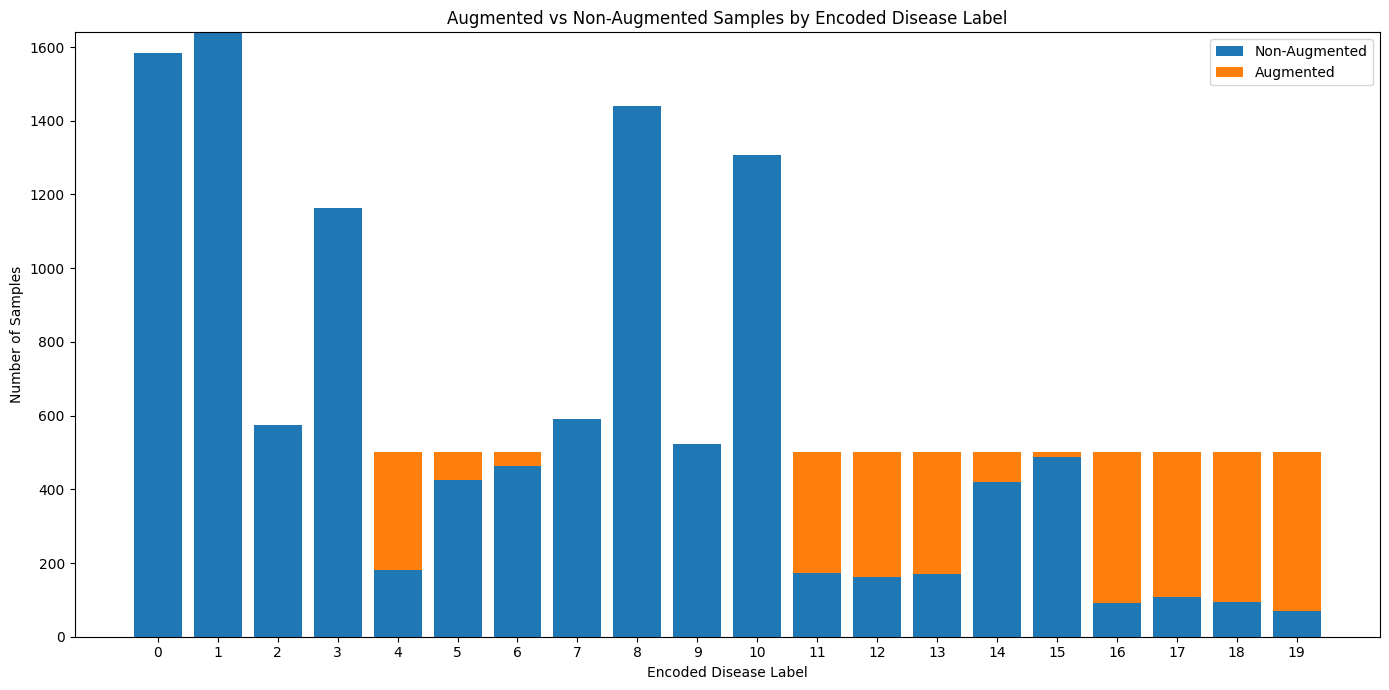

In [17]:
## EDA 3: Augmented vs Non-Augmented Samples by Encoded Label

# Create a mapping from disease class to encoded label
class_to_label = dict(
    zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))
)

# Total final training samples for each class
eda3_data = final_distribution.copy()

# Convert disease classes to encoded labels
eda3_data["Encoded Label"] = eda3_data["Class"].map(class_to_label)

# Count augmented samples for each encoded label
augmented_encoded_counts = (
    augmented_labels_df["Encoded Label"]
    .value_counts()
)

# Add augmented counts
eda3_data["Augmented"] = (
    eda3_data["Encoded Label"]
    .map(augmented_encoded_counts)
    .fillna(0)
)

# Calculate non-augmented samples
eda3_data["Non-Augmented"] = (
    eda3_data["Final_Count"] - eda3_data["Augmented"]
)

# Sort by encoded label 0–19
eda3_data = eda3_data.sort_values("Encoded Label")

# Plot stacked bar chart
plt.figure(figsize=(14, 7))

plt.bar(
    eda3_data["Encoded Label"],
    eda3_data["Non-Augmented"],
    label="Non-Augmented"
)

plt.bar(
    eda3_data["Encoded Label"],
    eda3_data["Augmented"],
    bottom=eda3_data["Non-Augmented"],
    label="Augmented"
)

plt.xlabel("Encoded Disease Label")
plt.ylabel("Number of Samples")
plt.title("Augmented vs Non-Augmented Samples by Encoded Disease Label")

plt.xticks(range(20))
plt.legend()

plt.tight_layout()

plt.savefig(
    "EDA_3_Augmented_vs_Non_Augmented_Encoded.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

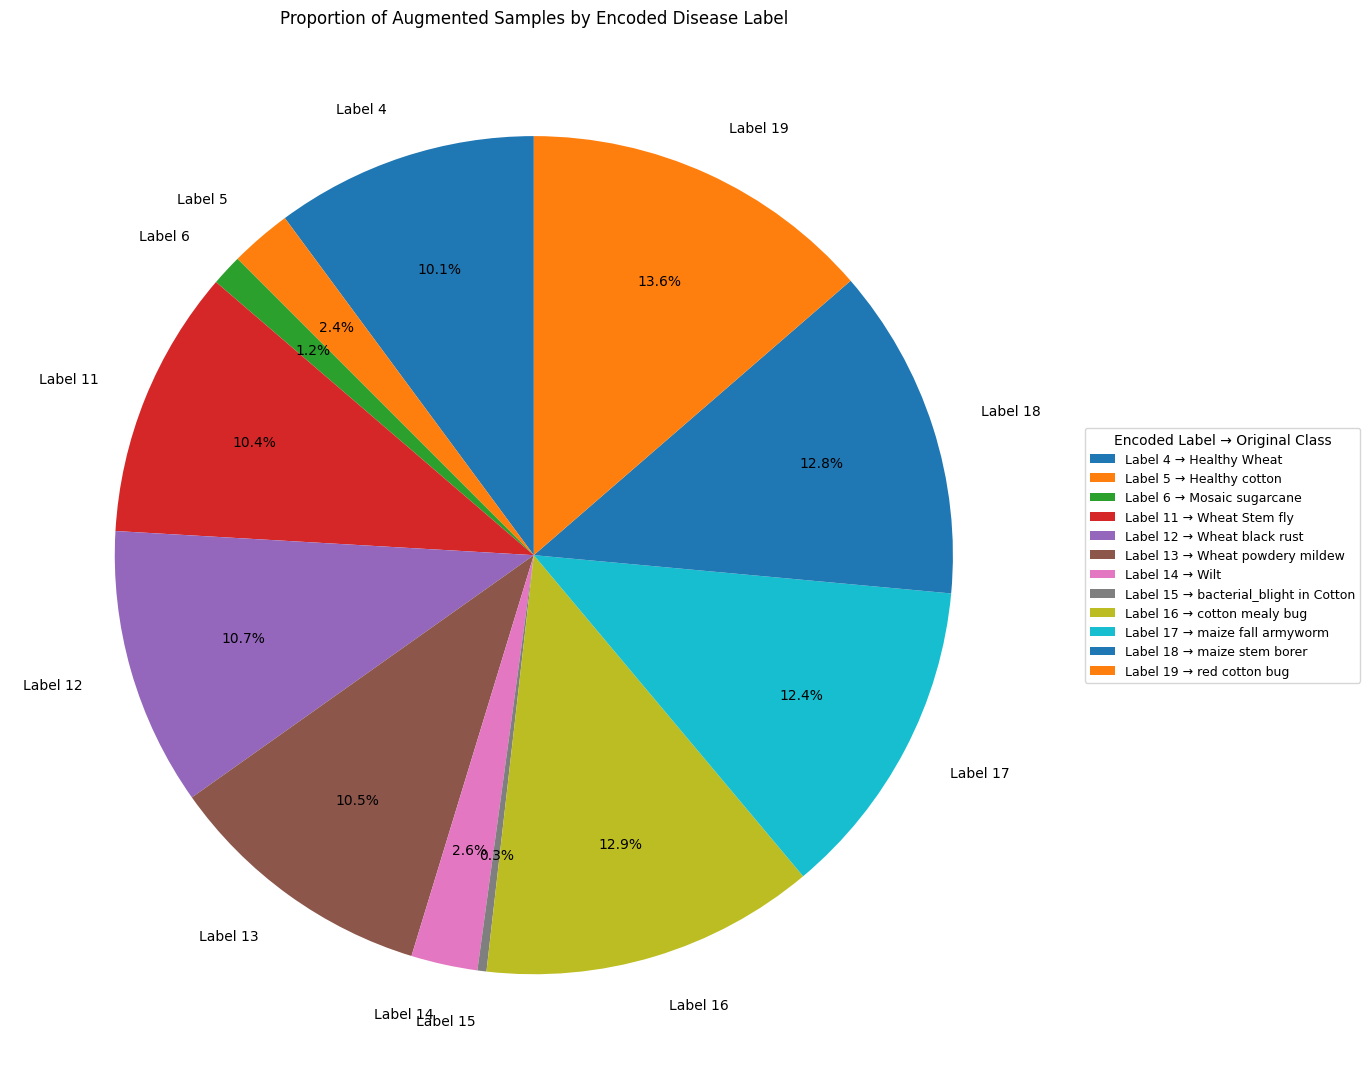

Number of augmented classes: 12


In [18]:
## EDA 4: Proportion of Augmented Samples by Encoded Label

# Select only the 12 classes that have augmented samples
augmented_data = final_distribution[
    final_distribution["Augmented_Count"] > 0
].copy()

# Convert original class names to encoded labels
class_to_label = dict(
    zip(
        label_encoder.classes_,
        label_encoder.transform(label_encoder.classes_)
    )
)

augmented_data["Encoded Label"] = (
    augmented_data["Class"].map(class_to_label)
)

# Sort according to encoded labels
augmented_data = augmented_data.sort_values("Encoded Label")

# Create labels shown around the pie
pie_labels = [
    f"Label {label}"
    for label in augmented_data["Encoded Label"]
]

# Create information for the original class names
legend_labels = [
    f"Label {label} → {class_name}"
    for label, class_name in zip(
        augmented_data["Encoded Label"],
        augmented_data["Class"]
    )
]

# Plot pie chart
plt.figure(figsize=(15, 11))

wedges, texts, autotexts = plt.pie(
    augmented_data["Augmented_Count"],
    labels=pie_labels,
    autopct="%1.1f%%",
    startangle=90,
    labeldistance=1.12,
    pctdistance=0.72,
    textprops={"fontsize": 10}
)

# Show original class names beside the pie
plt.legend(
    wedges,
    legend_labels,
    title="Encoded Label → Original Class",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=9,
    title_fontsize=10
)

plt.title(
    "Proportion of Augmented Samples by Encoded Disease Label"
)

plt.tight_layout()

plt.savefig(
    "EDA_4_Augmented_Encoded_Label_Proportion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Number of augmented classes:", len(augmented_data))

In [19]:
##Original Labels vs Encoded Labels
comparison = pd.DataFrame({
    "Original Class": label_encoder.classes_,
    "Encoded Label": label_encoder.transform(
        label_encoder.classes_
    )
})

display(comparison)

,Original Class,Encoded Label
0,Becterial Blight in Rice,0
1,Brownspot,1
2,Gray_Leaf_Spot,2
3,Healthy Maize,3
4,Healthy Wheat,4
5,Healthy cotton,5
6,Mosaic sugarcane,6
7,RedRot sugarcane,7
8,Rice Blast,8
9,Sugarcane Healthy,9


In [20]:
## Save Label Mapping

output_path = os.path.join(
    project_path,
    "Member_4_IT25103567_Outputs"
)

os.makedirs(
    output_path,
    exist_ok=True
)

mapping_file = os.path.join(
    output_path,
    "label_mapping.csv"
)

label_mapping.to_csv(
    mapping_file,
    index=False
)

print("Label mapping saved successfully!")
print("Saved to:", mapping_file)

Label mapping saved successfully!
Saved to: /content/drive/MyDrive/member 3/Crop Disease AI project/Member_4_IT25103567_Outputs/label_mapping.csv


In [21]:
## Save Augmented Encoded Labels

augmented_labels_file = os.path.join(
    output_path,
    "augmented_encoded_labels.csv"
)

augmented_labels_df.to_csv(
    augmented_labels_file,
    index=False
)

print("Augmented encoded labels saved successfully!")
print("Saved to:", augmented_labels_file)

Augmented encoded labels saved successfully!
Saved to: /content/drive/MyDrive/member 3/Crop Disease AI project/Member_4_IT25103567_Outputs/augmented_encoded_labels.csv


In [22]:
##Verify Saved Outputs
print("Member 4 output files:\n")

for file_name in os.listdir(output_path):
    print("-", file_name)

Member 4 output files:

- label_mapping.csv
- augmented_encoded_labels.csv


## Conclusion




*Categorical label encoding was successfully applied to the crop disease dataset.

*The 20 categorical disease classes were assigned unique numerical labels using the Label Encoder technique.

*The label mapping was verified to contain 20 unique labels ranging from 0 to 19.

*The class names from Member 3's final training distribution were used to establish the complete label mapping, while the augmented samples produced by Member 3 were encoded using the same mapping.

*The encoded label information was saved as output files for use in the subsequent stages of the machine-learning pipeline.



